<a href="https://colab.research.google.com/github/jukagoncalves/sistemas-inteligentes/blob/main/atividades/atividade-03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Carregando dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="wine_class")

In [ ]:
# Normalização (padronização Z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# Classificadores
dt_model = DecisionTreeClassifier(criterion='entropy', random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)

# Cross-validation (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# Função para avaliar modelos
def evaluate_model(model, name):
    print(f"\n=========== {name} ===========")
    scores = cross_validate(model, X_scaled, y, cv=cv,
                            scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
                            return_estimator=True)

    print(f"Acurácia média: {scores['test_accuracy'].mean():.4f}")
    print(f"Precisão média: {scores['test_precision_macro'].mean():.4f}")
    print(f"Recall médio:   {scores['test_recall_macro'].mean():.4f}")
    print(f"F1-score médio: {scores['test_f1_macro'].mean():.4f}")

    # Usar último modelo treinado para matriz de confusão
    final_model = scores['estimator'][-1]
    y_pred = final_model.predict(X_scaled)
    cm = confusion_matrix(y, y_pred, labels=final_model.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=final_model.classes_)
    disp.plot(cmap="Blues")
    plt.title(f"Matriz de Confusão - {name}")
    plt.show()

    print("\nRelatório de classificação:")
    print(classification_report(y, y_pred))


=========== ÁRVORE DE DECISÃO (ENTROPIA) ===========
Acurácia média: 0.9095
Precisão média: 0.9188
Recall médio:   0.9056
F1-score médio: 0.9089


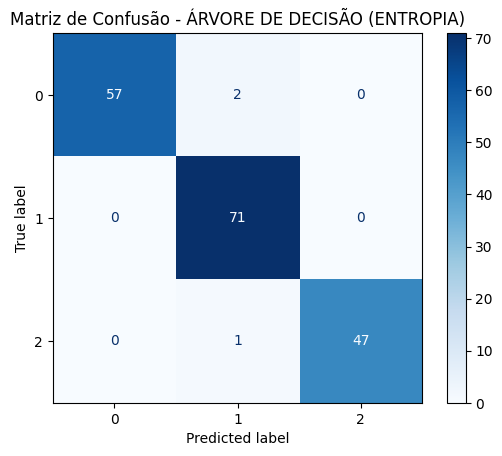


Relatório de classificação:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        59
           1       0.96      1.00      0.98        71
           2       1.00      0.98      0.99        48

    accuracy                           0.98       178
   macro avg       0.99      0.98      0.98       178
weighted avg       0.98      0.98      0.98       178


=========== KNN (k=5) ===========
Acurácia média: 0.9717
Precisão média: 0.9703
Recall médio:   0.9765
F1-score médio: 0.9721


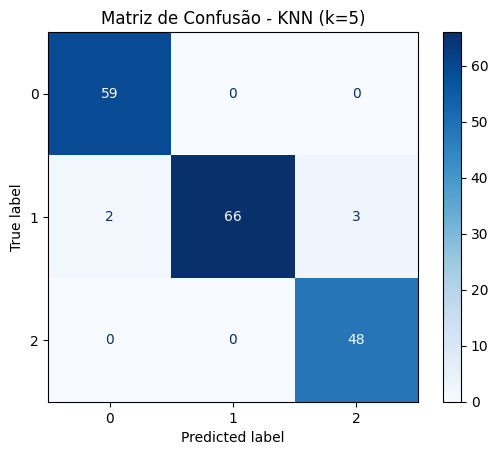


Relatório de classificação:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        59
           1       1.00      0.93      0.96        71
           2       0.94      1.00      0.97        48

    accuracy                           0.97       178
   macro avg       0.97      0.98      0.97       178
weighted avg       0.97      0.97      0.97       178



In [ ]:
# Avaliar modelos
evaluate_model(dt_model, "ÁRVORE DE DECISÃO (ENTROPIA)")
evaluate_model(knn_model, "KNN (k=5)")